# Super League 2025/26 — Season Review
**Analisis 1: Perburuan gelar Borneo FC vs Persib Bandung**
**Analisis 3: Kualitas tim lewat xG for vs xG against**

Sumber data: SofaScore (hasil scraping), `team_match_summary.csv` dan `team_season_summary.csv`.
Notebook ini sengaja memakai data **per pertandingan** untuk xG, karena kolom xG di file musiman kosong
untuk 8 tim (cukup satu laga tanpa xG, total musimannya ikut jadi NaN).

## 0. Setup

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
from pathlib import Path

DATA = Path('../data')   # folder data di root repo
OUT = Path('figures'); OUT.mkdir(exist_ok=True)

# Palet: satu warna per tim yang jadi fokus, sisanya abu-abu (emphasis, bukan pelangi)
C = {'Persib Bandung': '#2a78d6', 'Borneo FC Samarinda': '#eb6834', 'Persija Jakarta': '#6250d6'}
GREY, INK, MUTED, GRID = '#b4b2a9', '#1f1f1d', '#77756f', '#e7e5df'

plt.rcParams.update({
    'figure.dpi': 120, 'savefig.dpi': 200, 'savefig.bbox': 'tight',
    'font.family': 'DejaVu Sans', 'font.size': 10, 'text.color': INK,
    'axes.edgecolor': '#c3c2b7', 'axes.labelcolor': MUTED, 'axes.titleweight': 'bold',
    'axes.titlesize': 13, 'axes.titlelocation': 'left', 'axes.titlepad': 26, 'axes.grid': True, 'grid.color': GRID,
    'axes.spines.top': False, 'axes.spines.right': False,
    'xtick.color': MUTED, 'ytick.color': MUTED,
})

tm = pd.read_csv(DATA / 'team_match_summary.csv', parse_dates=['match_date'])
ts = pd.read_csv(DATA / 'team_season_summary.csv')
tm = tm.sort_values(['team', 'match_date']).reset_index(drop=True).copy()
import warnings; warnings.filterwarnings('ignore', category=pd.errors.PerformanceWarning)
print(tm.shape, '| tim:', tm.team.nunique(), '| pekan:', tm['round'].min(), '-', tm['round'].max())

(610, 130) | tim: 18 | pekan: 1 - 34


## 1. Cek kualitas data

In [2]:
cov = (tm.groupby('team')
         .agg(laga=('match_id', 'size'), laga_dgn_xg=('xg_for', 'count'))
         .assign(xg_musiman_kosong=lambda d: d.index.map(ts.set_index('team').xg_for.isna())))
cov.sort_values('laga_dgn_xg')

,laga,laga_dgn_xg,xg_musiman_kosong
team,,,
Java United FC,34,32,True
Borneo FC Samarinda,34,33,True
Dewa United FC,34,33,True
Madura United FC,34,33,True
PSBS Biak,33,33,False
Persik Kediri,34,33,True
Persis Solo,33,33,False
PSM Makassar,34,33,True
Persija Jakarta,34,33,True


Hampir semua laga punya xG (32–34 per tim). Yang kosong di file musiman hanyalah akibat 1–2 laga yang hilang.
Jadi metrik xG di bawah dihitung **per laga yang punya data xG**, bukan total, supaya adil antar tim.
Persis Solo dan PSBS Biak hanya punya 33 laga di dataset.

## 2. Analisis 1 — Perburuan gelar

In [3]:
tm['match_no'] = tm.groupby('team').cumcount() + 1
tm['cum_pts'] = tm.groupby('team').points.cumsum()
tm['cum_gd'] = tm.groupby('team').goal_difference.cumsum()

final = (tm.groupby('team').agg(pts=('points', 'sum'), gd=('goal_difference', 'sum'),
                                 gf=('goals_for', 'sum'), ga=('goals_against', 'sum'))
           .sort_values(['pts', 'gd'], ascending=False))
final.head(5)

,pts,gd,gf,ga
team,,,,
Borneo FC Samarinda,79,43,74,31
Persib Bandung,79,37,59,22
Persija Jakarta,71,36,65,29
Persebaya Surabaya,58,26,61,35
Java United FC,53,15,68,53


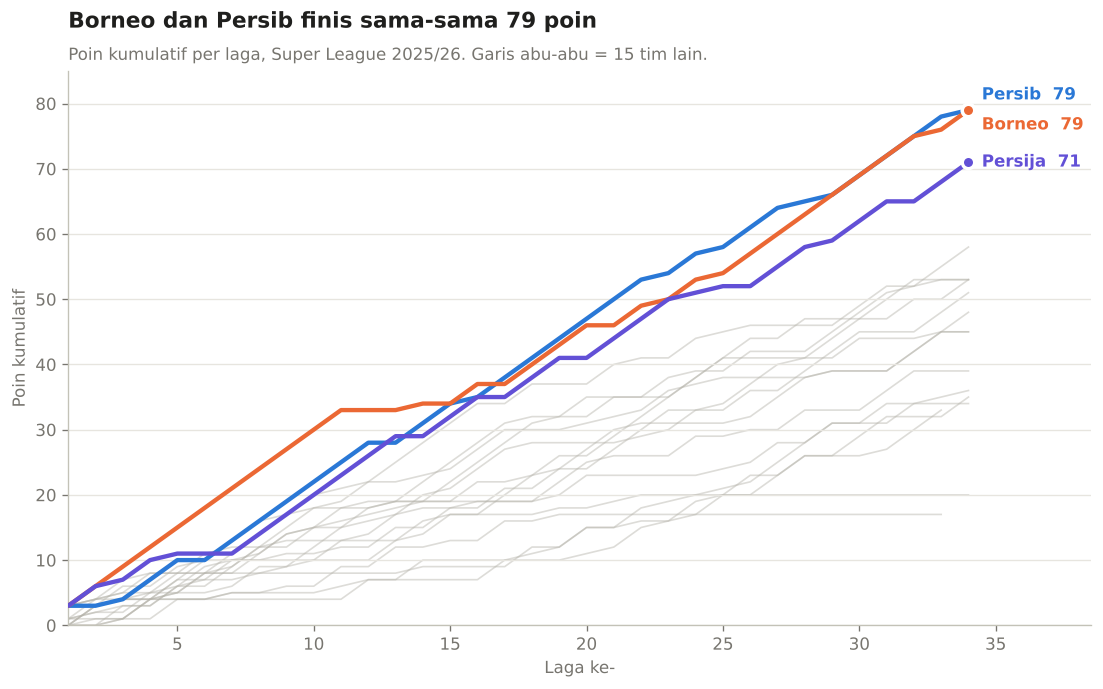

In [4]:
fig, ax = plt.subplots(figsize=(11, 6))
for team, d in tm.groupby('team'):
    if team not in C:
        ax.plot(d.match_no, d.cum_pts, color=GREY, lw=1, alpha=.45, zorder=1)
for team, col in C.items():
    d = tm[tm.team == team]
    ax.plot(d.match_no, d.cum_pts, color=col, lw=2.6, zorder=3, solid_capstyle='round')
    ax.scatter(d.match_no.iloc[-1], d.cum_pts.iloc[-1], color=col, s=55, zorder=4, edgecolor='white', lw=2)
    ax.annotate(f"{team.replace(' FC Samarinda', '').replace(' Bandung', '').replace(' Jakarta', '')}  {d.cum_pts.iloc[-1]}",
                (d.match_no.iloc[-1], d.cum_pts.iloc[-1]), xytext=(8, 0), textcoords='offset points',
                va='center', color=col, fontweight='bold')
    if team == 'Persib Bandung': ax.texts[-1].set_position((8, 9))
    if team == 'Borneo FC Samarinda': ax.texts[-1].set_position((8, -9))

ax.set_xlim(1, 38.5); ax.set_ylim(0, 85)
ax.set_xlabel('Laga ke-'); ax.set_ylabel('Poin kumulatif')
ax.grid(axis='x', visible=False)
ax.set_title('Borneo dan Persib finis sama-sama 79 poin')
ax.text(0, 1.02, 'Poin kumulatif per laga, Super League 2025/26. Garis abu-abu = 15 tim lain.',
        transform=ax.transAxes, color=MUTED)
fig.savefig(OUT / '01_title_race.png'); plt.show()

### 2b. Selisih poin Persib terhadap Borneo
Garis kumulatif bagus untuk gambaran besar, tapi selisihnya lebih jelas kalau diplot langsung.

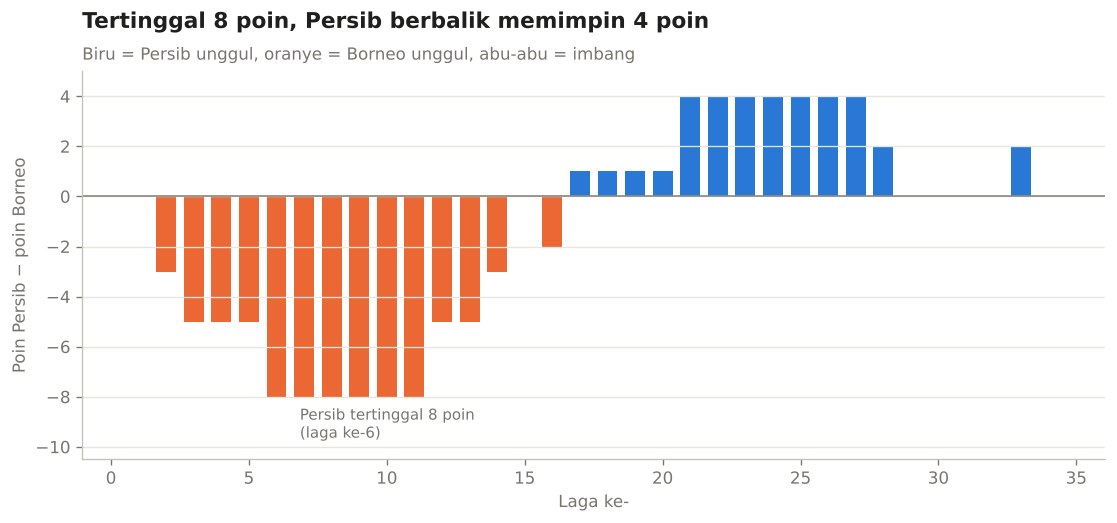

Laga Persib di atas Borneo: 13 | imbang: 7 | di bawah: 14


In [5]:
b = tm[tm.team == 'Borneo FC Samarinda'].set_index('match_no').cum_pts
p = tm[tm.team == 'Persib Bandung'].set_index('match_no').cum_pts
gap = (p - b)

fig, ax = plt.subplots(figsize=(11, 4.2))
ax.bar(gap.index, gap.values, width=.72,
       color=[C['Persib Bandung'] if v > 0 else C['Borneo FC Samarinda'] if v < 0 else GREY for v in gap])
ax.axhline(0, color='#888780', lw=1)
ax.set_xlabel('Laga ke-'); ax.set_ylabel('Poin Persib − poin Borneo')
ax.grid(axis='x', visible=False)
ax.yaxis.set_major_locator(mticker.MultipleLocator(2))
lo = gap.idxmin()
ax.annotate(f'Persib tertinggal {abs(gap.min())} poin\n(laga ke-{lo})', (lo, gap.min()),
            xytext=(14, -6), textcoords='offset points', ha='left', va='top', color=MUTED, fontsize=9)
ax.set_ylim(gap.min() - 2.5, gap.max() + 1)
ax.set_title('Tertinggal 8 poin, Persib berbalik memimpin 4 poin')
ax.text(0, 1.03, 'Biru = Persib unggul, oranye = Borneo unggul, abu-abu = imbang', transform=ax.transAxes, color=MUTED)
fig.savefig(OUT / '02_points_gap.png'); plt.show()
print('Laga Persib di atas Borneo:', (gap > 0).sum(), '| imbang:', (gap == 0).sum(), '| di bawah:', (gap < 0).sum())

### 2c. Form: rolling xG difference (5 laga)
Poin bisa menipu dalam jangka pendek. Rolling xG difference menunjukkan siapa yang sebenarnya lebih dominan di lapangan.

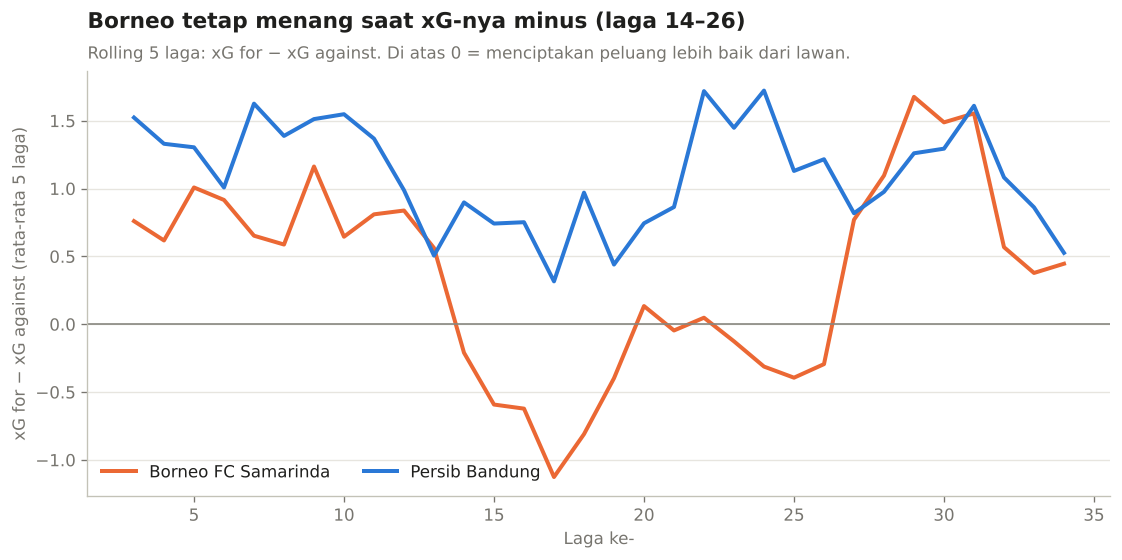

In [6]:
tm['xgd'] = tm.xg_for - tm.xg_against
tm['xgd_roll5'] = tm.groupby('team').xgd.transform(lambda s: s.rolling(5, min_periods=3).mean())

fig, ax = plt.subplots(figsize=(11, 4.6))
for team in ['Borneo FC Samarinda', 'Persib Bandung']:
    d = tm[tm.team == team]
    ax.plot(d.match_no, d.xgd_roll5, color=C[team], lw=2.4, label=team)
ax.axhline(0, color='#888780', lw=1)
ax.set_xlabel('Laga ke-'); ax.set_ylabel('xG for − xG against (rata-rata 5 laga)')
ax.grid(axis='x', visible=False)
ax.legend(frameon=False, loc='lower left', ncol=2)
ax.set_title('Borneo tetap menang saat xG-nya minus (laga 14–26)')
ax.text(0, 1.03, 'Rolling 5 laga: xG for − xG against. Di atas 0 = menciptakan peluang lebih baik dari lawan.', transform=ax.transAxes, color=MUTED)
fig.savefig(OUT / '03_rolling_xgd.png'); plt.show()

## 3. Analisis 3 — Kualitas tim: xG for vs xG against

In [7]:
q = (tm.dropna(subset=['xg_for', 'xg_against'])
       .groupby('team')
       .agg(laga_xg=('xg_for', 'size'), xg_for=('xg_for', 'mean'), xg_against=('xg_against', 'mean'),
            gf=('goals_for', 'mean'), ga=('goals_against', 'mean'))
       .join(final[['pts']]))
q['xgd'] = q.xg_for - q.xg_against
q['finishing'] = q.gf - q.xg_for          # + = cetak gol lebih banyak dari peluangnya
q['keeping'] = q.xg_against - q.ga        # + = kebobolan lebih sedikit dari peluang lawan
q.sort_values('xgd', ascending=False).round(2)

,laga_xg,xg_for,xg_against,gf,ga,pts,xgd,finishing,keeping
team,,,,,,,,,
Persib Bandung,34,1.96,0.87,1.74,0.65,79,1.09,-0.23,0.22
Persija Jakarta,33,1.79,0.77,1.94,0.85,71,1.02,0.15,-0.08
Borneo FC Samarinda,33,1.91,1.52,2.18,0.94,79,0.40,0.27,0.58
Persebaya Surabaya,34,1.61,1.31,1.79,1.03,58,0.30,0.18,0.29
Dewa United FC,33,1.50,1.28,1.30,1.09,53,0.22,-0.19,0.19
Bhayangkara Presisi Lampung FC,34,1.49,1.31,1.56,1.32,53,0.18,0.07,-0.02
Java United FC,32,1.67,1.53,1.97,1.53,53,0.15,0.30,-0.01
Persita Tangerang,34,1.33,1.20,1.12,1.09,45,0.13,-0.21,0.11
Bali United FC,34,1.62,1.54,1.68,1.41,51,0.08,0.06,0.13


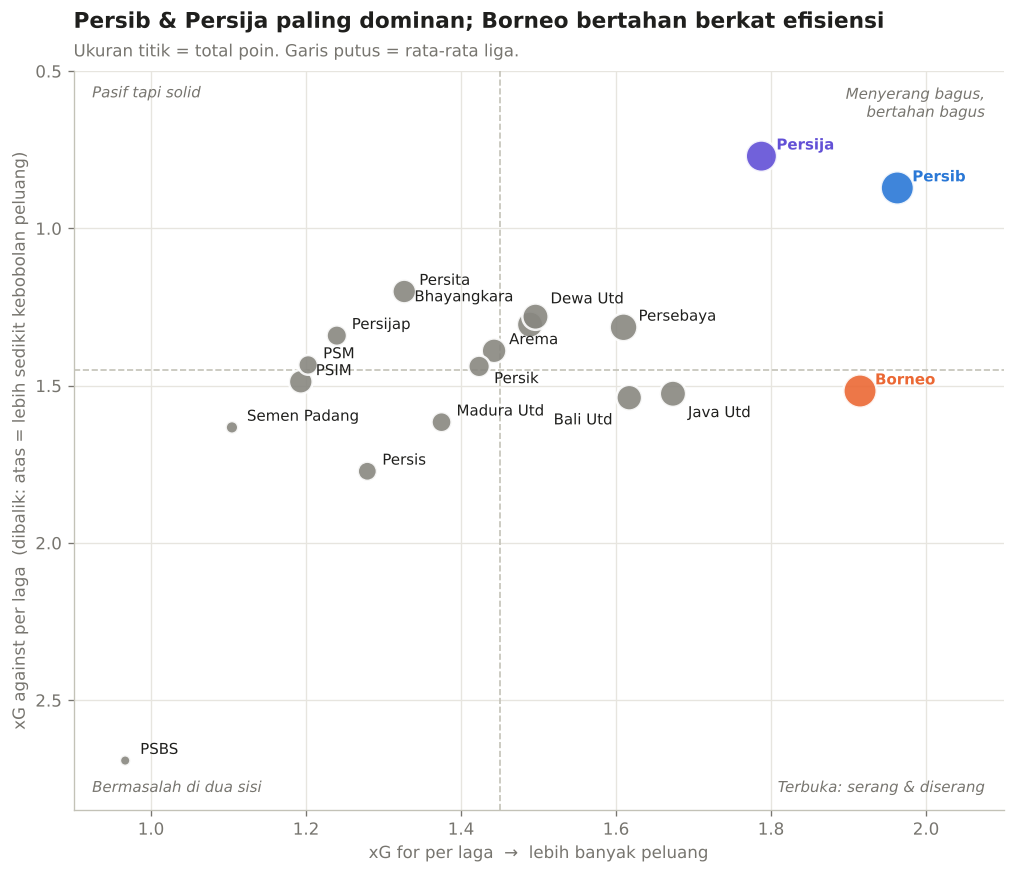

In [8]:
fig, ax = plt.subplots(figsize=(10, 8))
mx, my = q.xg_for.mean(), q.xg_against.mean()
ax.axvline(mx, color='#c3c2b7', lw=1, ls='--'); ax.axhline(my, color='#c3c2b7', lw=1, ls='--')

sizes = 40 + (q.pts - q.pts.min()) / (q.pts.max() - q.pts.min()) * 360
cols = [C.get(t, '#888780') for t in q.index]
ax.scatter(q.xg_for, q.xg_against, s=sizes, c=cols, alpha=.9, edgecolor='white', lw=1.5, zorder=3)
for t, r in q.iterrows():
    short = (t.replace(' FC Samarinda', '').replace(' Presisi Lampung FC', '').replace(' United FC', ' Utd')
              .replace(' FC', '').replace(' Bandung', '').replace(' Jakarta', '').replace(' Surabaya', '')
              .replace(' Tangerang', '').replace(' Yogyakarta', '').replace(' Kediri', '').replace(' Jepara', '')
              .replace(' Makassar', '').replace(' Solo', '').replace(' Biak', ''))
    off = {'Dewa Utd': (9, 8), 'Bhayangkara': (-10, 14), 'Bali Utd': (-10, -16), 'Java Utd': (9, -14), 'Persik': (9, -10)}.get(short, (9, 4))
    ax.annotate(short, (r.xg_for, r.xg_against), xytext=off, ha='right' if off[0] < 0 else 'left', textcoords='offset points', fontsize=9,
                color=C.get(t, INK), fontweight='bold' if t in C else 'normal')

ax.set_ylim(2.85, 0.5); ax.set_xlim(.9, 2.1)   # atas = kebobolan peluang lebih sedikit = lebih baik
kw = dict(transform=ax.transAxes, color=MUTED, fontsize=9, style='italic')
ax.text(.98, .98, 'Menyerang bagus,\nbertahan bagus', ha='right', va='top', **kw)
ax.text(.02, .98, 'Pasif tapi solid', ha='left', va='top', **kw)
ax.text(.98, .02, 'Terbuka: serang & diserang', ha='right', va='bottom', **kw)
ax.text(.02, .02, 'Bermasalah di dua sisi', ha='left', va='bottom', **kw)
ax.set_xlabel('xG for per laga  →  lebih banyak peluang')
ax.set_ylabel('xG against per laga  (dibalik: atas = lebih sedikit kebobolan peluang)')
ax.set_title('Persib & Persija paling dominan; Borneo bertahan berkat efisiensi')
ax.text(0, 1.02, 'Ukuran titik = total poin. Garis putus = rata-rata liga.', transform=ax.transAxes, color=MUTED)
fig.savefig(OUT / '04_xg_quadrant.png'); plt.show()

### 3b. Over/underperformance: gol aktual vs xG
Melengkapi kuadran: tim mana yang poinnya "didorong" finishing tajam atau kiper yang sedang bagus.

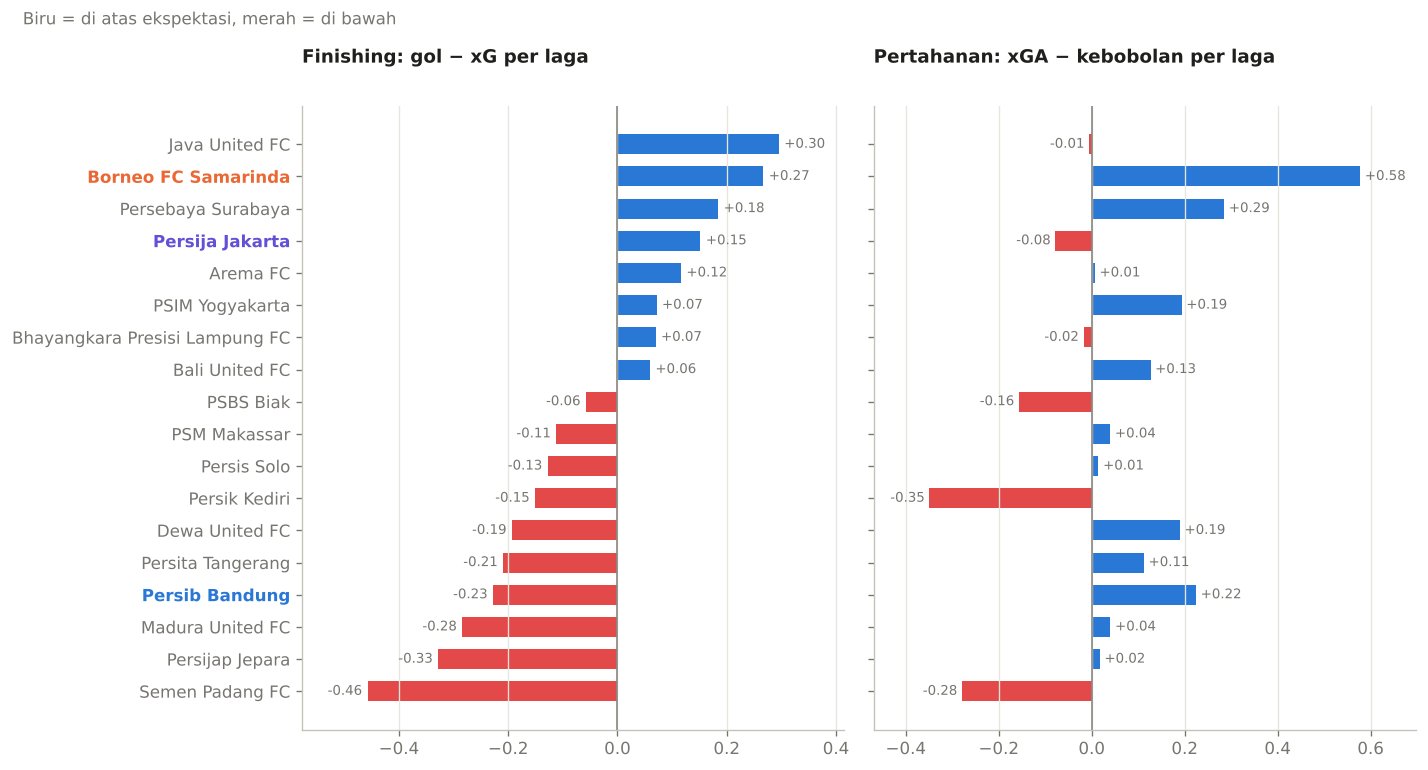

In [9]:
o = q.sort_values('finishing')
fig, axes = plt.subplots(1, 2, figsize=(12, 6.5), sharey=True)
for ax, col, title in [(axes[0], 'finishing', 'Finishing: gol − xG per laga'),
                       (axes[1], 'keeping', 'Pertahanan: xGA − kebobolan per laga')]:
    v = o[col]
    ax.barh(o.index, v, height=.62, color=['#2a78d6' if x > 0 else '#e34948' for x in v])
    ax.axvline(0, color='#888780', lw=1)
    ax.set_title(title, fontsize=11); ax.grid(axis='y', visible=False)
    ax.set_xlim(v.min() - .12, v.max() + .12)
    for i, (t, x) in enumerate(v.items()):
        ax.text(x + (.01 if x >= 0 else -.01), i, f'{x:+.2f}', va='center',
                ha='left' if x >= 0 else 'right', fontsize=8, color=MUTED)
    for lbl in ax.get_yticklabels():
        if lbl.get_text() in C: lbl.set_color(C[lbl.get_text()]); lbl.set_fontweight('bold')
fig.suptitle('Biru = di atas ekspektasi, merah = di bawah', x=.02, ha='left', color=MUTED, fontsize=10)
fig.tight_layout(); fig.savefig(OUT / '05_over_under.png'); plt.show()

## 4. Ringkasan angka kunci

In [10]:
key = q.loc[['Borneo FC Samarinda', 'Persib Bandung', 'Persija Jakarta']].join(final[['gd']])
key[['pts', 'gd', 'xg_for', 'xg_against', 'xgd', 'finishing', 'keeping']].round(2)

,pts,gd,xg_for,xg_against,xgd,finishing,keeping
team,,,,,,,
Borneo FC Samarinda,79,43,1.91,1.52,0.40,0.27,0.58
Persib Bandung,79,37,1.96,0.87,1.09,-0.23,0.22
Persija Jakarta,71,36,1.79,0.77,1.02,0.15,-0.08


## 5. Insight & catatan
- Tulis 3–4 bullet insight di sini setelah melihat grafik (lihat ringkasan di chat).
- **Keterbatasan:** xG versi SofaScore; beberapa laga tanpa xG dikecualikan; urutan memakai tanggal laga
  (laga tunda membuat "laga ke-n" tidak selalu sama dengan "pekan ke-n").
- **Tie-breaker juara** di Super League memakai head-to-head lebih dulu, bukan selisih gol — cek hasil kedua laga Borneo vs Persib.

In [11]:
h2h = tm[(tm.team == 'Persib Bandung') & (tm.opponent == 'Borneo FC Samarinda')]
h2h[['match_date', 'round', 'side', 'goals_for', 'goals_against', 'result', 'xg_for', 'xg_against']]

,match_date,round,side,goals_for,goals_against,result,xg_for,xg_against
384,2025-12-05 12:00:00+00:00,4,home,3,1,W,2.32,0.82
397,2026-03-15 13:30:00+00:00,21,away,1,1,D,1.86,2.70
